Given a 1D SDE of the form
$$dX_t = \mu(X_t,t)\, dt + \sigma(X_t,t)\, dw_t,$$
the corresponding Fokker-Planck (or Forward Kolmogorov, more generally) equation is
$$\frac{\partial p}{\partial t}(x,t) = -\frac{\partial}{\partial x}\big[ \mu(x,t)p(x,t) \big] + \frac{1}{2} \frac{\partial^2}{\partial x^2} \big[ \sigma^2(x,t)p(x,t) \big].$$
The numerical scheme is slightly simpler and faster in the autonomous case $\mu(x,t) = \mu(x)$ and $\sigma(x,t) = \sigma(x)$. Some notes about this equation: Despite the nonlinear advection term, the diffusion prevents the formation of shocks. I could try using a single-step scheme, or I could use operator splitting and solve the advection/diffusion equations separately.

In [36]:
import numpy as np
import matplotlib.pyplot as plt
import scipy as sp

''' Autonomous Forward-Kolmogorov PDE solver using the Finite Volume Crank-Nicholson method '''

class FK_PDE_autonomous:
    def __init__(self, mu, sigma_sqrd):
        self.mu = mu
        self.sigma_sqrd = sigma_sqrd

    def solve_IVP(self, init_cond, tmax, xmax, dt, dx, method='FVCN'):
        match method:
            case 'FVCN': return self._solve_IVP_FVCN_(init_cond, tmax, xmax, dt, dx)
            case _: return self._solve_IVP_FVCN_(init_cond, tmax, xmax, dt, dx)

    def _solve_IVP_FVCN_(self, init_cond, tmax, xmax, dt, dx):
        '''The solution matrix U will have the cell centers [c_0, ..., c_J] and [t_0, ..., t_T]'''
        self.T = T = int(np.ceil(tmax / dt)) # ensure dt (actual) is less than that given by the user
        self.J = J = int(np.ceil(xmax / dx)) # ensure dx (actual) is less than that given by the user
        self.c_array = np.linspace(0, xmax, J+1, endpoint=True)
        self.t_array = np.linspace(0, tmax, T+1, endpoint=True)
        self.mu_array = np.array([self.mu(c) for c in self.c_array])
        self.sigma_sqrd_array = np.array([self.sigma_sqrd(x) for x in self.c_array])
        r1 = dt / (4*dx)
        r2 = dt / (4*dx*dx)

        U = np.zeros((T+1, J+1)) 

        U[0] = init_cond(self.c_array) # Use initial condition to set U at t=0
        mass_correction = 1 / (np.sum(U[0,:]) * dx)
        U[0,:] *= mass_correction # Normalize initial condition to have total mass 1

        T_upper_diag = np.zeros((J+1))
        T_diag = np.zeros((J+1))
        T_lower_diag = np.zeros((J+1))

        ''' Each step requires solving the tridiagonal system T U(n+1) = M U(n). Note T and M depend on mu and sigma_sqrd but are independent of time '''
        T_diag[0] = 1 + r1*self.mu_array[0] + r2*self.sigma_sqrd_array[0] # Overwrite for BC
        T_diag[1:J] = 1 + 2*r2*self.sigma_sqrd_array[1:J]
        T_diag[J] = 1 - r1*self.mu_array[J] + r2*self.sigma_sqrd_array[J] # Overwrite for BC
        T_upper_diag[1:] = r1*self.mu_array[1:] - r2*self.sigma_sqrd_array[1:]
        T_lower_diag[:J] = -(r1*self.mu_array[:J] + r2*self.sigma_sqrd_array[:J])

        # Build banded matrix for scipy solver
        T_banded = np.zeros((3, self.J+1))
        T_banded[0] = T_upper_diag
        T_banded[1] = T_diag
        T_banded[2] = T_lower_diag

        # Build M sparse matrix
        M_upper_diag = -T_upper_diag[1:]
        M_diag = 2 - T_diag
        M_lower_diag = -T_lower_diag[:J]
        M_sparse = sp.sparse.diags([M_upper_diag, M_diag, M_lower_diag], [1, 0, -1]).tocsr()

        # Solve the tridiagonal system at each time step
        for n in range(1,T+1):
            U[n] = self.__crank_nicholson_step__(U[n-1], T_banded, M_sparse)

        return U

    def __crank_nicholson_step__(self, Uprev, T_banded, M_sparse):
        b = M_sparse @ Uprev
        return sp.linalg.solve_banded((1,1), T_banded, b)

## Simple SDE model to test the numerical scheme

C:\Users\daths\AppData\Local\Temp\ipykernel_14980\3039633370.py:11: RuntimeWarning: divide by zero encountered in divide
  return np.exp(-1 / (1 - np.power(s*(x-c),2)))


Total mass at t=0: 0.44399
Total mass at t=5: 0.44399


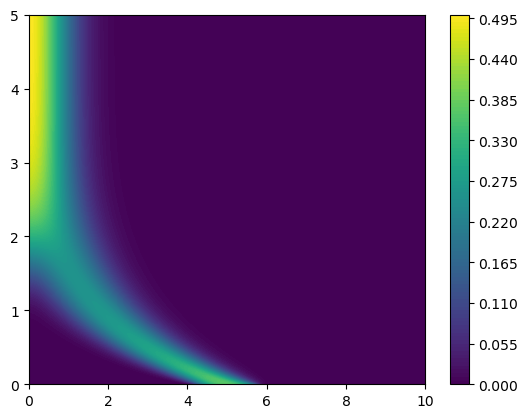

In [2]:
import matplotlib.pyplot as plt

def mu(x): 
    return -x
def sigma_sqrd(x): 
    return 1

fpobj = FK_PDE_autonomous(mu, sigma_sqrd)

def bump_function(x, s, c):
    return np.exp(-1 / (1 - np.power(s*(x-c),2)))

def bump_function_vectorized(x, s, c):
    return np.where((x > c - 1/s) & (x < c + 1/s), bump_function(x, s, c), 0)

def init_cond(x):
    return bump_function_vectorized(x, s=1, c=5)

xmax = 10
tmax = 5
dt = 0.001
dx = 0.005
sol = fpobj.solve_IVP(init_cond, tmax, xmax, dt, dx, method='FVCN')

X, T = np.meshgrid(fpobj.c_array, fpobj.t_array, indexing='xy')
plt.contourf(X, T, sol, levels=100)
plt.colorbar()

print(f'Total mass at t=0: {np.sum(sol[0,:]) * dx:.5f}')
print(f'Total mass at t={tmax:.0f}: {np.sum(sol[-1,:]) * dx:.5f}')

plt.savefig('Figures/test-2.png')

In [3]:
# Parameters
rho = 1600 # in [100, 2,000]
alpha = 60000 # in [10,000, 100,000]
K = 0.25 # in [0,1]
delta = 1 # in [0,2]
N = 1 # in [0,2]
c = 1.5e-4 # in [1e-6, 1e-4]

def QS_expression(S):
    return rho + (alpha*np.pow(S,2)) / (np.pow(K,2) + np.pow(S,2))

def mu(S):
    return c*QS_expression(S)*N - delta*S

def sigma_sqrd(S):
    return c*QS_expression(S)*N + delta*S

In [77]:
import numpy as np
import matplotlib.pyplot as plt
import scipy as sp

''' Non-autonomous Forward-Kolmogorov PDE solver using the Finite Volume Crank-Nicholson method '''

class FK_PDE_non_autonomous:
    def __init__(self, mu, sigma_sqrd):
        """
        Initializes the FK_PDE_non_autonomous class with drift and diffusion functions μ(x,t) and σ²(x,t).
        """
        self.mu = mu
        self.sigma_sqrd = sigma_sqrd

    def solve_IVP(self, init_cond, tmax, xmax, dt, dx, method='FVCN'):
        """
        Wrapper function to solve the initial value problem (IVP) for the non-autonomous Fokker-Planck equation
        using the specified xmax, tmax, dx, dt, and numerical method.
        """
        self.tmax = tmax
        self.xmax = xmax
        self.dt = dt
        self.dx = dx

        self.U = self.__initialize_solution_matrix__(init_cond)

        match method:
            case 'FVCN': return self.__solve_IVP_FVCN__(self.U)
            case _: return self.__solve_IVP_FVCN__(self.U)

    def __initialize_solution_matrix__(self, init_cond):
        """
        Initializes the solution matrix U with the cell centers [c_0, ..., c_J] and times [t_0, ..., t_T]
        """
        self.T = T = int(np.ceil(self.tmax / self.dt)) # ensure dt (actual) is less than that given by the user
        self.J = J = int(np.ceil(self.xmax / self.dx)) # ensure dx (actual) is less than that given by the user
        self.c_array = np.linspace(0, self.xmax, J+1, endpoint=True)
        self.t_array = np.linspace(0, self.tmax, T+1, endpoint=True)

        U = np.zeros((T+1, J+1)) # Allocate space for U
        U[0] = init_cond(self.c_array) # Use initial condition to set U at t=0
        mass_correction = 1 / (np.sum(U[0,:]) * self.dx)
        U[0,:] *= mass_correction # Normalize initial condition to have total mass 1
        return U

    def __solve_IVP_FVCN__(self, U):
        """
        Wrapper function to solves the IVP using the Finite Volume Crank-Nicholson (FVCN) method.
        """
        # Build the initial T and M matrices
        T_banded, M_sparse = self.__build_initial_FVCD_matrices__()

        # Solve the tridiagonal system at each time step
        for n in range(1, self.T+1):
            T_banded, M_sparse = self.__build_new_FVCD_matrices__(n, T_banded, M_sparse)
            U[n] = self.__crank_nicholson_step__(U[n-1], T_banded, M_sparse)

        return U
    
    def __build_initial_FVCD_matrices__(self):
        """
        Builds the initial T and M matrices for the FVCD method
        """
        mu_array_0, sigma_sqrd_array_0 = self.__get_mu_sigma_arrays__(0)
        mu_array_1, sigma_sqrd_array_1 = self.__get_mu_sigma_arrays__(1)

        r1 = self.dt / (4*self.dx)  # dt / (4*dx)
        r2 = self.dt / (4*self.dx*self.dx)  # dt / (4*dx*dx)

        # Build banded T matrix for scipy solver
        T_banded = np.zeros((3, self.J+1))
        T_banded = self.__build_new_T_banded__(T_banded, mu_array_1, sigma_sqrd_array_1, r1, r2)

        # Allocate space for M matrix diagonals
        M_upper_diag = np.zeros((self.J))
        M_diag = np.zeros((self.J+1))
        M_lower_diag = np.zeros((self.J))

        # Build M matrix diagonals
        M_diag[0] = 1 - r1*mu_array_0[0] - r2*sigma_sqrd_array_0[0] # Overwrite for BC
        M_diag[1:self.J] = 1 - 2*r2*sigma_sqrd_array_0[1:self.J]
        M_diag[self.J] = 1 + r1*mu_array_0[self.J] - r2*sigma_sqrd_array_0[self.J] # Overwrite for BC
        M_upper_diag = - (r1*mu_array_0[1:] - r2*sigma_sqrd_array_0[1:])
        M_lower_diag = r1*mu_array_0[:self.J] + r2*sigma_sqrd_array_0[:self.J]

        # Build sparse M matrix for scipy solver
        M_sparse = (sp.sparse.diags([M_upper_diag, M_diag, M_lower_diag], [1, 0, -1], shape=(self.J+1, self.J+1))).tocsr()

        return T_banded, M_sparse
    
    ''' Returns mu(x,t) and sigma^2(x,t) arrays at time step n '''
    def __get_mu_sigma_arrays__(self, n):
        mu_array = np.array([self.mu(c, self.t_array[n]) for c in self.c_array])
        sigma_sqrd_array = np.array([self.sigma_sqrd(c, self.t_array[n]) for c in self.c_array])
        return mu_array, sigma_sqrd_array
    
    def __build_new_FVCD_matrices__(self, n, T_banded, M_sparse):
        """
        Builds the updated T and M matrices for the FVCD method at time step n using previous T_banded. 
        This takes advantage of the fact that the diagonals of M(n+1) can be computed from T(n).
        """
        # Compute updated mu and sigma_sqrd values at time step n
        mu_array_next, sigma_sqrd_array_next = self.__get_mu_sigma_arrays__(n)

        r1 = self.dt / (4*self.dx)  # dt / (4*dx)
        r2 = self.dt / (4*self.dx*self.dx)  # dt / (4*dx*dx)

        # Build M matrix diagonals using previous T matrix diagonals
        M_upper_diag = - T_banded[0][1:]
        M_diag = 2 - T_banded[1]
        M_lower_diag = - T_banded[2][:self.J]

        # Build sparse M matrix for scipy solver
        M_sparse = sp.sparse.diags([M_upper_diag, M_diag, M_lower_diag], [1, 0, -1]).tocsr()

        # Update T matrix diagonals in T_banded_prev
        T_banded = self.__build_new_T_banded__(T_banded, mu_array_next, sigma_sqrd_array_next, r1, r2)

        return T_banded, M_sparse

    def __build_new_T_banded__(self, T_banded, mu_array_next, sigma_sqrd_array_next, r1, r2):
        """
        Builds the updated T matrix diagonals in T_banded using the new mu and sigma_sqrd arrays
        """
        T_banded[1][0] = 1 + r1*mu_array_next[0] + r2*sigma_sqrd_array_next[0] # Overwrite for BC
        T_banded[1][1:self.J] = 1 + 2*r2*sigma_sqrd_array_next[1:self.J] # Main diagonal
        T_banded[1][self.J] = 1 - r1*mu_array_next[self.J] + r2*sigma_sqrd_array_next[self.J] # Overwrite for BC
        T_banded[0][1:] = r1*mu_array_next[1:] - r2*sigma_sqrd_array_next[1:] # Upper diagonal
        T_banded[2][:self.J] = -(r1*mu_array_next[:self.J] + r2*sigma_sqrd_array_next[:self.J]) # Lower diagonal
        return T_banded

    def __crank_nicholson_step__(self, Uprev, T_banded, M_sparse):
        """
        Performs one step of the Crank-Nicholson method by solving the linear system T U(n+1) = M U(n).
        """
        b = M_sparse @ Uprev
        return sp.linalg.solve_banded((1,1), T_banded, b)

C:\Users\daths\AppData\Local\Temp\ipykernel_14980\2906216947.py:11: RuntimeWarning: divide by zero encountered in divide
  return np.exp(-1 / (1 - np.power(s*(x-c),2)))


Total mass at t=0: 1.00000000
Total mass at t=5: 1.00000000


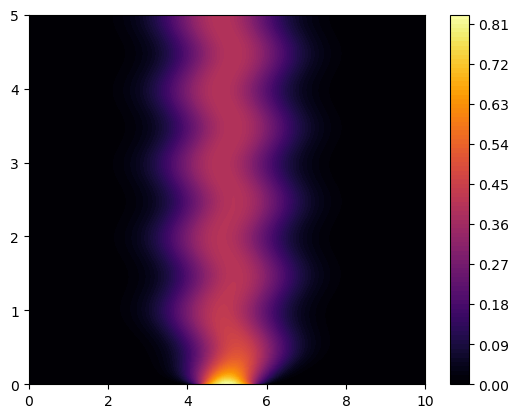

In [78]:
import matplotlib.pyplot as plt

def mu(x,t): 
    return np.sin(2*np.pi*t) + 5-x
def sigma_sqrd(x,t): 
    return 2

fpobj = FK_PDE_non_autonomous(mu, sigma_sqrd)

def bump_function(x, s, c):
    return np.exp(-1 / (1 - np.power(s*(x-c),2)))

def bump_function_vectorized(x, s, c):
    return np.where((x > c - 1/s) & (x < c + 1/s), bump_function(x, s, c), 0)

def init_cond(x):
    #return np.where((x >= 4) & (x < 6), 0.5, 0)
    return bump_function_vectorized(x, s=1, c=5)

xmax = 10
tmax = 5
dt = 0.01
dx = 0.01
sol = fpobj.solve_IVP(init_cond, tmax, xmax, dt, dx, method='FVCN')
#sol = fpobj.solve_IVP_adaptive_dt(init_cond, xmax, tmax, dx, dt='adaptive', method='FVCN')

X, T = np.meshgrid(fpobj.c_array, fpobj.t_array, indexing='xy')
plt.contourf(X, T, sol, cmap='inferno', levels=100)
plt.colorbar()

print(f'Total mass at t=0: {np.sum(sol[0,:]) * dx:.8f}')
print(f'Total mass at t={tmax:.0f}: {np.sum(sol[-1,:]) * dx:.8f}')

plt.savefig('Figures/non-autonomous-test.png')

## Benchmarking autonomous vs. non-autonomous solver

In [79]:
import time

def mu(x): 
    return 5 - x
def sigma_sqrd(x): 
    return 2

fpobj_autonomous = FK_PDE_autonomous(mu, sigma_sqrd)
fpobj_non_autonomous = FK_PDE_non_autonomous(lambda x, t: mu(x), lambda x, t: sigma_sqrd(x))

def bump_function(x, s, c):
    return np.exp(-1 / (1 - np.power(s*(x-c),2)))

def bump_function_vectorized(x, s, c):
    return np.where((x > c - 1/s) & (x < c + 1/s), bump_function(x, s, c), 0)

def init_cond(x):
    return bump_function_vectorized(x, s=1, c=5)

xmax = 10
tmax = 5
dt = 0.001
dx = 0.01

autonomous_start = time.perf_counter()
sol_autonomous = fpobj_autonomous.solve_IVP(init_cond, tmax, xmax, dt, dx, method='FVCN')
autonomous_end = time.perf_counter()

non_autonomous_start = time.perf_counter()
sol_non_autonomous = fpobj_non_autonomous.solve_IVP(init_cond, tmax, xmax, dt, dx, method='FVCN')
non_autonomous_end = time.perf_counter()

print(f"Time elapsed (autonomous): {autonomous_end - autonomous_start:.6f} seconds")
print(f"Time elapsed (non-autonomous): {non_autonomous_end - non_autonomous_start:.6f} seconds")

print(f'Are solutions equal? {bool(not np.any(np.abs(sol_autonomous - sol_non_autonomous)))}')

C:\Users\daths\AppData\Local\Temp\ipykernel_14980\1889939439.py:12: RuntimeWarning: divide by zero encountered in divide
  return np.exp(-1 / (1 - np.power(s*(x-c),2)))


Time elapsed (autonomous): 0.512332 seconds
Time elapsed (non-autonomous): 6.592080 seconds
Are solutions equal? True


## Testing the QS Model

C:\Users\daths\AppData\Local\Temp\ipykernel_14980\883459872.py:21: RuntimeWarning: divide by zero encountered in divide
  return np.exp(-1 / (1 - np.power(s*(x-c),2)))


Finished solving PDE.
Total mass at t=0: 1.00000000
Total mass at t=40: 1.00000000


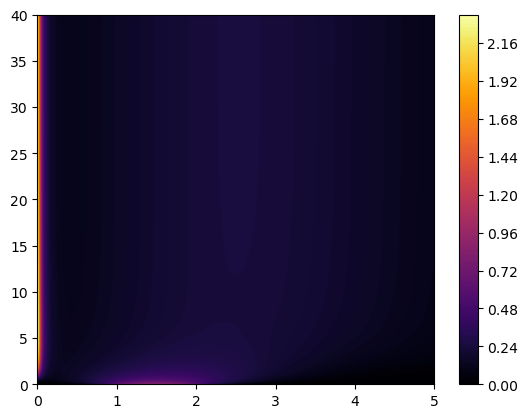

In [80]:
# Parameters
rho = 1600 # in [100, 2,000]
alpha = 60000 # in [10,000, 100,000]
K = 0.25 # in [0,1]
delta = 0.2 # in [0,2]
N = 1 # in [0,2]
c = 1e-5 # in [1e-6, 1e-4]

''' Drift and noise functions'''
def QS_expression(S):
    return rho + (alpha*np.pow(S,2)) / (np.pow(K,2) + np.pow(S,2))

def mu(S):
    return c*QS_expression(S)*N - delta*S

def sigma_sqrd(S):
    return c*QS_expression(S)*N + delta*S

''' Constructing the initial condition '''
def bump_function(x, s, c):
    return np.exp(-1 / (1 - np.power(s*(x-c),2)))

def bump_function_vectorized(x, s, c):
    return np.where((x > c - 1/s) & (x < c + 1/s), bump_function(x, s, c), 0)

def init_cond(x):
    return bump_function_vectorized(x, s=1, c=1.5)

fpobj = FK_PDE_autonomous(mu, sigma_sqrd)

xmax = 5
tmax = 40
dt = 0.005
dx = 0.005

sol = fpobj.solve_IVP(init_cond, tmax, xmax, dt, dx, method='FVCN')

print('Finished solving PDE.')

X, T = np.meshgrid(fpobj.c_array, fpobj.t_array, indexing='xy')
plt.contourf(X, T, sol, cmap='inferno', levels=200)
plt.colorbar()

print(f'Total mass at t=0: {np.sum(sol[0,:]) * dx:.8f}')
print(f'Total mass at t={tmax:.0f}: {np.sum(sol[-1,:]) * dx:.8f}')

plt.savefig('Figures/QS-model-FVCN-test.png')

## More sophisticated test: the CIR model
$$dX(t) = \kappa(\theta - X(t))dt + \sigma\sqrt{X(t)}\, dw(t)$$
The final probability distribution is known analytically, so we can compare the numerical solution with the true distribution.

C:\Users\daths\AppData\Local\Temp\ipykernel_14980\1173336269.py:15: RuntimeWarning: divide by zero encountered in divide
  return np.exp(-1 / (1 - np.power(s*(x-c),2)))


Finished solving PDE.


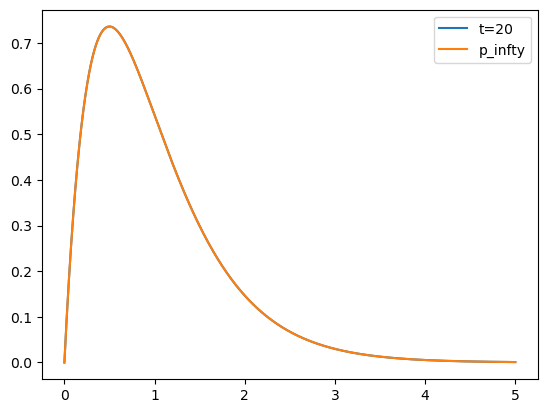

In [81]:
# Parameters
kappa = 1
theta = 1
sigma = 1

''' Drift and noise functions'''
def mu(x): 
    return kappa*(theta - x)

def sigma_sqrd(x):
    return sigma*x

''' Constructing the initial condition '''
def bump_function(x, s, c):
    return np.exp(-1 / (1 - np.power(s*(x-c),2)))

def bump_function_vectorized(x, s, c):
    return np.where((x > c - 1/s) & (x < c + 1/s), bump_function(x, s, c), 0)

def init_cond(x):
    return bump_function_vectorized(x, s=1, c=1.5)

fpobj = FK_PDE_autonomous(mu, sigma_sqrd)

xmax = 5
tmax = 20
dt = 0.01
dx = 0.001

sol = fpobj.solve_IVP(init_cond, tmax, xmax, dt, dx, method='FVCN')

print('Finished solving PDE.')

def p_infty(x):
    beta = (2*kappa)/(sigma*sigma)
    alpha = (2*kappa*theta)/(sigma*sigma)
    return ( (beta**alpha) / sp.special.gamma(alpha) ) * (x**(alpha-1)) * np.exp(-beta*x)

plt.plot(fpobj.c_array, sol[-1,:], label=f't={tmax:.0f}')
plt.plot(fpobj.c_array, p_infty(fpobj.c_array), label='p_infty')
plt.legend()

## FP_PDE class that handles autonomous and non-autonomous drift and noise.

In [82]:
import numpy as np
import matplotlib.pyplot as plt
import scipy as sp

''' Non-autonomous Forward-Kolmogorov PDE solver using the Finite Volume Crank-Nicholson method '''

class FP_PDE:
    def __init__(self, mu, sigma_sqrd, autonomous=False):
        """
        Initializes the FP_PDE class with drift and diffusion functions μ(x,t) and σ²(x,t).
        """
        self.mu = mu
        self.sigma_sqrd = sigma_sqrd
        self.autonomous = autonomous

    def solve_IVP(self, init_cond, tmax, xmax, dt, dx, method='FVCN'):
        """
        Wrapper function to solve the initial value problem (IVP) for the non-autonomous Fokker-Planck equation
        using the specified xmax, tmax, dx, dt, and numerical method.
        """
        self.tmax = tmax
        self.xmax = xmax
        self.dt = dt
        self.dx = dx

        self.U = self.__initialize_solution_matrix__(init_cond)

        match method:
            case 'FVCN': return self.__solve_IVP_FVCN__(self.U)
            case _: return self.__solve_IVP_FVCN__(self.U)

    def __initialize_solution_matrix__(self, init_cond):
        """
        Initializes the solution matrix U with the cell centers [c_0, ..., c_J] and times [t_0, ..., t_T]
        """
        self.T = T = int(np.ceil(self.tmax / self.dt)) # ensure dt (actual) is less than that given by the user
        self.J = J = int(np.ceil(self.xmax / self.dx)) # ensure dx (actual) is less than that given by the user
        self.c_array = np.linspace(0, self.xmax, J+1, endpoint=True)
        self.t_array = np.linspace(0, self.tmax, T+1, endpoint=True)

        U = np.zeros((T+1, J+1)) # Allocate space for U
        U[0] = init_cond(self.c_array) # Use initial condition to set U at t=0
        mass_correction = 1 / (np.sum(U[0,:]) * self.dx)
        U[0,:] *= mass_correction # Normalize initial condition to have total mass 1
        return U

    def __solve_IVP_FVCN__(self, U):
        """
        Wrapper function to solves the IVP using the Finite Volume Crank-Nicholson (FVCN) method.
        """
        # Build the initial T and M matrices
        T_banded, M_sparse = self.__build_initial_FVCD_matrices__()

        # Solve the tridiagonal system at each time step
        for n in range(1, self.T+1):
            if not self.autonomous: T_banded, M_sparse = self.__build_new_FVCD_matrices__(n, T_banded, M_sparse)
            U[n] = self.__crank_nicholson_step__(U[n-1], T_banded, M_sparse)

        return U
    
    def __build_initial_FVCD_matrices__(self):
        """
        Builds the initial T and M matrices for the FVCD method
        """
        mu_array_0, sigma_sqrd_array_0 = self.__get_mu_sigma_arrays__(0)
        mu_array_1, sigma_sqrd_array_1 = self.__get_mu_sigma_arrays__(1)

        r1 = self.dt / (4*self.dx)  # dt / (4*dx)
        r2 = self.dt / (4*self.dx*self.dx)  # dt / (4*dx*dx)

        # Build banded T matrix for scipy solver
        T_banded = np.zeros((3, self.J+1))
        T_banded = self.__build_new_T_banded__(T_banded, mu_array_1, sigma_sqrd_array_1, r1, r2)

        # Allocate space for M matrix diagonals
        M_upper_diag = np.zeros((self.J))
        M_diag = np.zeros((self.J+1))
        M_lower_diag = np.zeros((self.J))

        # Build M matrix diagonals
        M_diag[0] = 1 - r1*mu_array_0[0] - r2*sigma_sqrd_array_0[0] # Overwrite for BC
        M_diag[1:self.J] = 1 - 2*r2*sigma_sqrd_array_0[1:self.J]
        M_diag[self.J] = 1 + r1*mu_array_0[self.J] - r2*sigma_sqrd_array_0[self.J] # Overwrite for BC
        M_upper_diag = - (r1*mu_array_0[1:] - r2*sigma_sqrd_array_0[1:])
        M_lower_diag = r1*mu_array_0[:self.J] + r2*sigma_sqrd_array_0[:self.J]

        # Build sparse M matrix for scipy solver
        M_sparse = (sp.sparse.diags([M_upper_diag, M_diag, M_lower_diag], [1, 0, -1], shape=(self.J+1, self.J+1))).tocsr()

        return T_banded, M_sparse
    
    ''' Returns mu(x,t) and sigma^2(x,t) arrays at time step n '''
    def __get_mu_sigma_arrays__(self, n):
        mu_array = np.array([self.mu(c, self.t_array[n]) for c in self.c_array])
        sigma_sqrd_array = np.array([self.sigma_sqrd(c, self.t_array[n]) for c in self.c_array])
        return mu_array, sigma_sqrd_array
    
    def __build_new_FVCD_matrices__(self, n, T_banded, M_sparse):
        """
        Builds the updated T and M matrices for the FVCD method at time step n using previous T_banded. 
        This takes advantage of the fact that the diagonals of M(n+1) can be computed from T(n).
        """
        # Compute updated mu and sigma_sqrd values at time step n
        mu_array_next, sigma_sqrd_array_next = self.__get_mu_sigma_arrays__(n)

        r1 = self.dt / (4*self.dx)  # dt / (4*dx)
        r2 = self.dt / (4*self.dx*self.dx)  # dt / (4*dx*dx)

        # Build M matrix diagonals using previous T matrix diagonals
        M_upper_diag = - T_banded[0][1:]
        M_diag = 2 - T_banded[1]
        M_lower_diag = - T_banded[2][:self.J]

        # Build sparse M matrix for scipy solver
        M_sparse = sp.sparse.diags([M_upper_diag, M_diag, M_lower_diag], [1, 0, -1]).tocsr()

        # Update T matrix diagonals in T_banded_prev
        T_banded = self.__build_new_T_banded__(T_banded, mu_array_next, sigma_sqrd_array_next, r1, r2)

        return T_banded, M_sparse

    def __build_new_T_banded__(self, T_banded, mu_array_next, sigma_sqrd_array_next, r1, r2):
        """
        Builds the updated T matrix diagonals in T_banded using the new mu and sigma_sqrd arrays
        """
        T_banded[1][0] = 1 + r1*mu_array_next[0] + r2*sigma_sqrd_array_next[0] # Overwrite for BC
        T_banded[1][1:self.J] = 1 + 2*r2*sigma_sqrd_array_next[1:self.J] # Main diagonal
        T_banded[1][self.J] = 1 - r1*mu_array_next[self.J] + r2*sigma_sqrd_array_next[self.J] # Overwrite for BC
        T_banded[0][1:] = r1*mu_array_next[1:] - r2*sigma_sqrd_array_next[1:] # Upper diagonal
        T_banded[2][:self.J] = -(r1*mu_array_next[:self.J] + r2*sigma_sqrd_array_next[:self.J]) # Lower diagonal
        return T_banded

    def __crank_nicholson_step__(self, Uprev, T_banded, M_sparse):
        """
        Performs one step of the Crank-Nicholson method by solving the linear system T U(n+1) = M U(n).
        """
        b = M_sparse @ Uprev
        return sp.linalg.solve_banded((1,1), T_banded, b)

## Benchmarking new FP_PDE class

In [83]:
# Parameters
kappa = 1
theta = 1
sigma = 1

''' Drift and noise functions'''
def mu(x,t): 
    return kappa*(theta - x)

def sigma_sqrd(x,t):
    return sigma*x

''' Constructing the initial condition '''
def bump_function(x, s, c):
    return np.exp(-1 / (1 - np.power(s*(x-c),2)))

def bump_function_vectorized(x, s, c):
    return np.where((x > c - 1/s) & (x < c + 1/s), bump_function(x, s, c), 0)

def init_cond(x):
    return bump_function_vectorized(x, s=1, c=1.5)

xmax = 5
tmax = 20
dt = 0.01
dx = 0.001

fpobj_autonomous = FP_PDE(mu, sigma_sqrd, autonomous=True)
fpobj_non_autonomous = FP_PDE(mu, sigma_sqrd, autonomous=False)

autonomous_start = time.perf_counter()
sol_autonomous = fpobj_autonomous.solve_IVP(init_cond, tmax, xmax, dt, dx, method='FVCN')
autonomous_end = time.perf_counter()

print('Finished solving autonomous PDE.')

non_autonomous_start = time.perf_counter()
sol_non_autonomous = fpobj_non_autonomous.solve_IVP(init_cond, tmax, xmax, dt, dx, method='FVCN')
non_autonomous_end = time.perf_counter()

print('Finished solving non-autonomous PDE.')

print(f"Time elapsed (autonomous): {autonomous_end - autonomous_start:.6f} seconds")
print(f"Time elapsed (non-autonomous): {non_autonomous_end - non_autonomous_start:.6f} seconds")

C:\Users\daths\AppData\Local\Temp\ipykernel_14980\278962737.py:15: RuntimeWarning: divide by zero encountered in divide
  return np.exp(-1 / (1 - np.power(s*(x-c),2)))


Finished solving autonomous PDE.
Finished solving non-autonomous PDE.
Time elapsed (autonomous): 0.455997 seconds
Time elapsed (non-autonomous): 10.897509 seconds
